In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import pandas as pd
import numpy as np

base = "/kaggle/input/datasets/dhoogla/unswnb15/"
train = pd.read_parquet(base + "UNSW_NB15_training-set.parquet")
test  = pd.read_parquet(base + "UNSW_NB15_testing-set.parquet")

print("Train shape:", train.shape)
print("Test shape: ", test.shape)
print("\nColumns:", train.columns.tolist())
print("\nSame columns in test?", list(train.columns) == list(test.columns))
print()
print(train.head())
print()
print(train.dtypes.value_counts())

# 1. Missing values and duplicates
miss = train.isnull().sum()
print("\nMissing values:\n", miss[miss > 0] if (miss > 0).any() else "None")
print("Duplicate rows (train):", train.duplicated().sum())
print("Duplicate rows (test): ", test.duplicated().sum())

# 2. Class balance, train AND test
for name, df in [("train", train), ("test", test)]:
    print(f"\n{name} label distribution:")
    print(df["label"].value_counts())
    print(df["label"].value_counts(normalize=True).round(3))

# 3. Attack categories
print("\nAttack categories (train):")
print(train["attack_cat"].value_counts())
print("\nAttack categories (test):")
print(test["attack_cat"].value_counts())

# 4. Categorical columns (catches both object and category dtypes)
cat_cols = train.select_dtypes(include=["object", "category"]).columns.tolist()
print("\nCategorical columns:", cat_cols)
for c in cat_cols:
    print(c, "->", train[c].nunique(), "unique values")

# 5. Numeric summary
pd.set_option("display.float_format", "{:.2f}".format)
print(train.describe().T[["mean", "std", "min", "max"]])

Train shape: (175341, 36)
Test shape:  (82332, 36)

Columns: ['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'is_sm_ips_ports', 'attack_cat', 'label']

Same columns in test? True

        dur proto service state  spkts  dpkts  sbytes  dbytes       rate  \
0  0.121478   tcp       -   FIN      6      4     258     172  74.087486   
1  0.649902   tcp       -   FIN     14     38     734   42014  78.473373   
2  1.623129   tcp       -   FIN      8     16     364   13186  14.170161   
3  1.681642   tcp     ftp   FIN     12     12     628     770  13.677108   
4  0.449454   tcp       -   FIN     10      6     534     268  33.373825   

          sload  ...  trans_depth  response_body

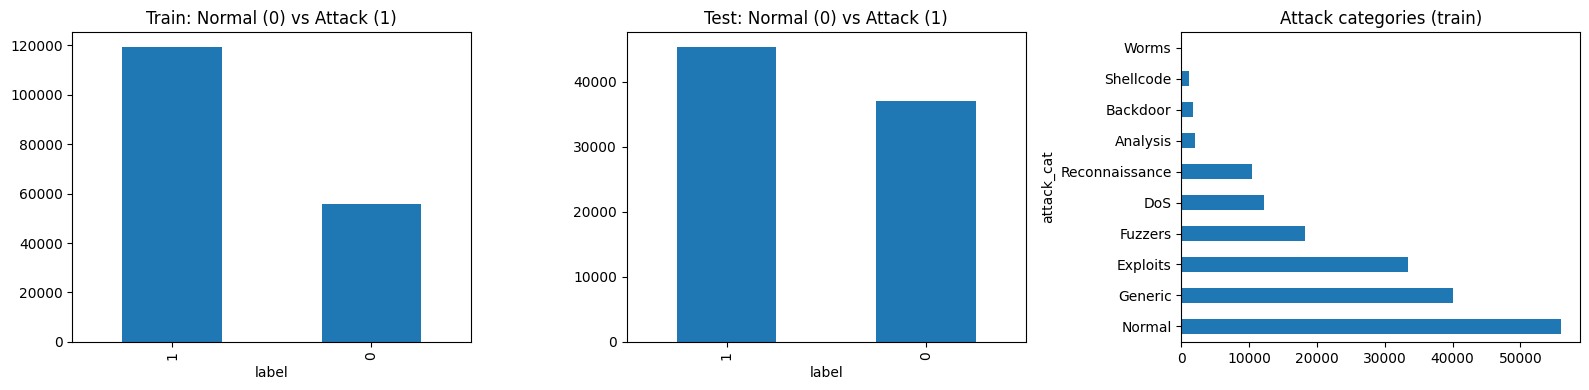

dload              -0.39
ct_dst_sport_ltm    0.36
dmean              -0.34
rate                0.34
swin               -0.33
dwin               -0.32
ct_src_dport_ltm    0.31
stcpb              -0.26
dtcpb              -0.25
is_sm_ips_ports    -0.18
sload               0.18
sinpkt             -0.18
dpkts              -0.12
ackdat              0.10
dloss              -0.09
Name: label, dtype: float64


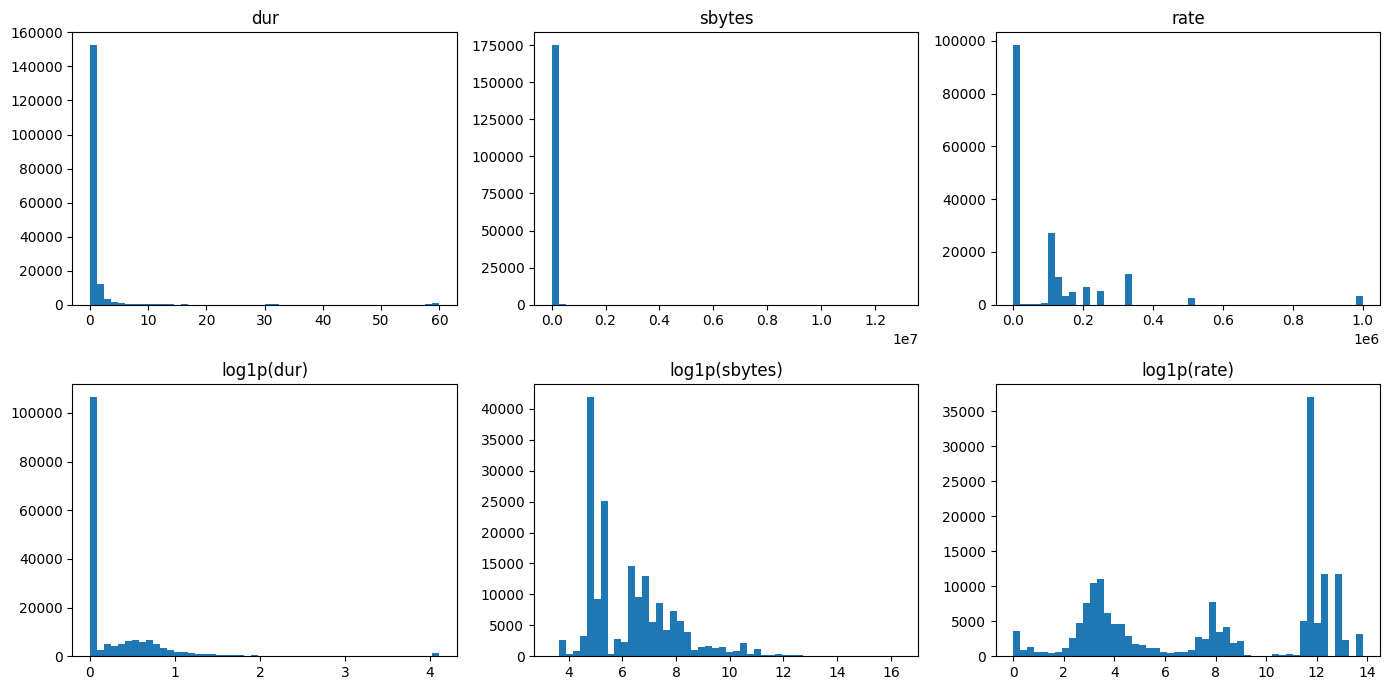

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
train["label"].value_counts().plot(kind="bar", ax=ax[0], title="Train: Normal (0) vs Attack (1)")
test["label"].value_counts().plot(kind="bar", ax=ax[1], title="Test: Normal (0) vs Attack (1)")
train["attack_cat"].value_counts().plot(kind="barh", ax=ax[2], title="Attack categories (train)")
plt.tight_layout(); plt.show()

# Correlation with label
num = train.select_dtypes(include=np.number)
corr = num.corr()["label"].drop("label").sort_values(key=abs, ascending=False)
print(corr.head(15))

# Skew check, on raw and log scale
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for i, col in enumerate(["dur", "sbytes", "rate"]):
    ax[0, i].hist(train[col], bins=50);            ax[0, i].set_title(col)
    ax[1, i].hist(np.log1p(train[col]), bins=50);  ax[1, i].set_title(f"log1p({col})")
plt.tight_layout(); plt.show()

In [3]:
#training script:

Train (deduped): (96822, 14) | attack share: 0.495
Test raw: (82332, 14) | Test deduped: (49971, 14)

=== 5-fold CV on deduplicated train ===
                       accuracy  precision  recall      f1  roc_auc
model                                                             
LogisticRegression      0.8194     0.7583  0.9323  0.8363   0.8674
DecisionTree            0.9072     0.8566  0.9760  0.9124   0.9667
RandomForest            0.9168     0.8953  0.9420  0.9181   0.9780
HistGradientBoosting    0.9169     0.8812  0.9618  0.9198   0.9786
Selected by CV F1: HistGradientBoosting

=== Official test set ===
                model   eval_set  accuracy  precision  recall     f1  roc_auc
  LogisticRegression   test_raw    0.7659     0.7132  0.9614 0.8189   0.8325
  LogisticRegression test_dedup    0.6754     0.5342  0.9112 0.6735   0.7393
        DecisionTree   test_raw    0.8237     0.7627  0.9870 0.8605   0.9634
        DecisionTree test_dedup    0.7675     0.6165  0.9715 0.7543   0.9337
  

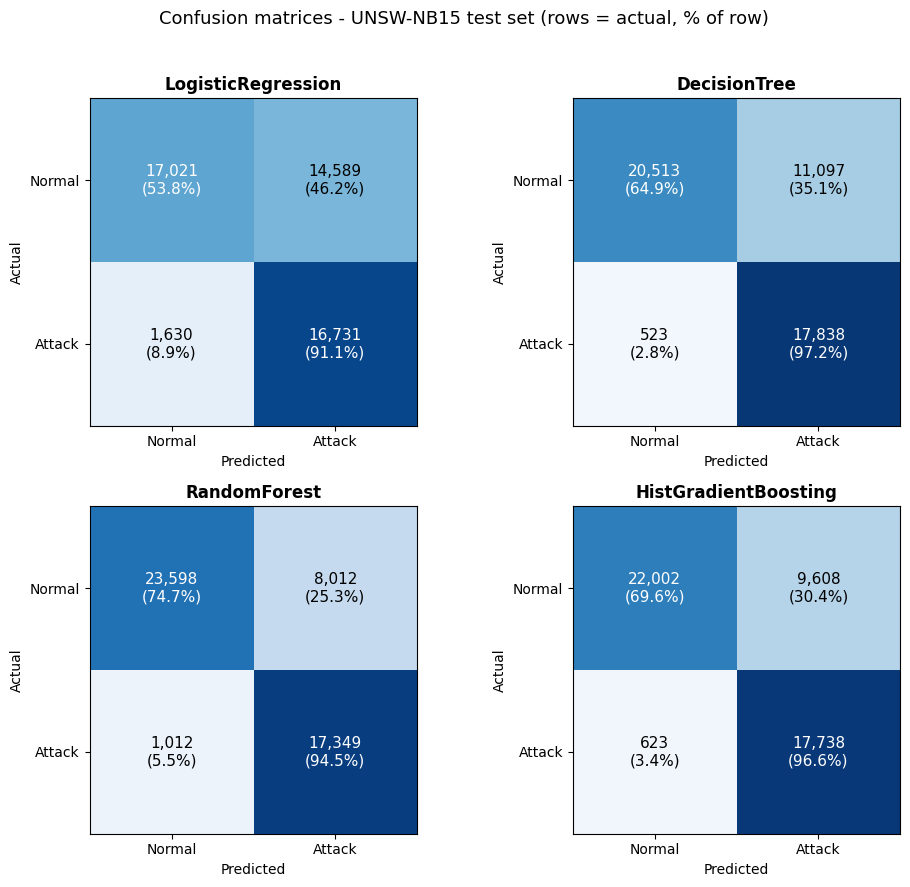

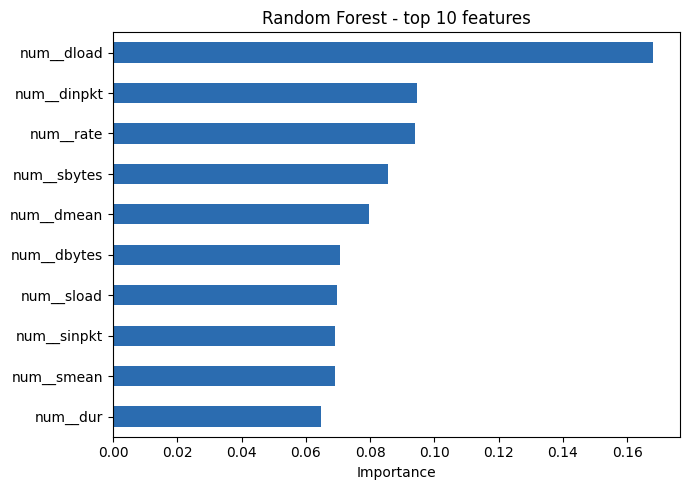


Saved to /kaggle/working/models and /kaggle/working/results

Saved to /kaggle/working/models and /kaggle/working/results


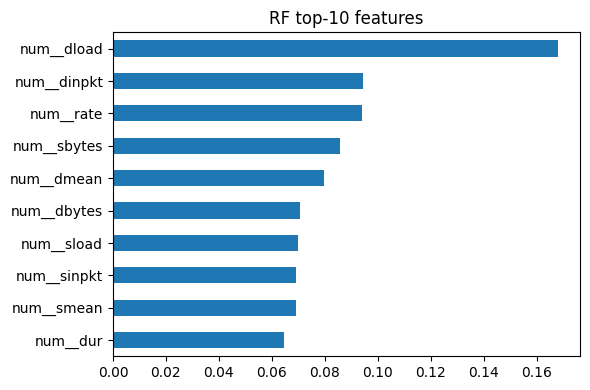

In [3]:
import json, joblib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)
warnings.filterwarnings("ignore")

# ---------- 1. Load ----------
base = "/kaggle/input/datasets/dhoogla/unswnb15/"
train_raw = pd.read_parquet(base + "UNSW_NB15_training-set.parquet")
test_raw  = pd.read_parquet(base + "UNSW_NB15_testing-set.parquet")

# ---------- 2. Feature schema (ONLY features the crypto app can compute) ----------
NUM = ["dur", "spkts", "dpkts", "sbytes", "dbytes", "rate",
       "sload", "dload", "sinpkt", "dinpkt", "smean", "dmean"]
CAT = ["proto", "state"]
FEATURES = NUM + CAT
TARGET = "label"          # attack_cat is NEVER a feature (label leakage)

def prep(df):
    X = df[FEATURES].copy()
    X[CAT] = X[CAT].astype(str)          # category dtype -> str
    return X, df[TARGET].values

train_dd = train_raw.drop_duplicates().reset_index(drop=True)
test_dd  = test_raw.drop_duplicates().reset_index(drop=True)
X_tr, y_tr = prep(train_dd)
X_te_raw, y_te_raw = prep(test_raw)
X_te_dd,  y_te_dd  = prep(test_dd)
print("Train (deduped):", X_tr.shape, "| attack share:", y_tr.mean().round(3))
print("Test raw:", X_te_raw.shape, "| Test deduped:", X_te_dd.shape)

# ---------- 3. Preprocessing ----------
ohe = lambda: OneHotEncoder(handle_unknown="infrequent_if_exist",
                            min_frequency=0.005, sparse_output=False)
# rare / unseen protocols and states are grouped automatically into "infrequent"

def pre_linear():   # log1p tames the huge skew, then scale (needed for LogReg)
    num = Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                    ("sc", StandardScaler())])
    return ColumnTransformer([("num", num, NUM), ("cat", ohe(), CAT)])

def pre_tree():     # trees are scale/skew invariant
    return ColumnTransformer([("num", "passthrough", NUM), ("cat", ohe(), CAT)])

# ---------- 4. Models ----------
models = {
    "LogisticRegression": Pipeline([("pre", pre_linear()),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "DecisionTree": Pipeline([("pre", pre_tree()),
        ("clf", DecisionTreeClassifier(max_depth=12, min_samples_leaf=5,
                                       class_weight="balanced", random_state=42))]),
    "RandomForest": Pipeline([("pre", pre_tree()),
        ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                       class_weight="balanced", n_jobs=-1, random_state=42))]),
    "HistGradientBoosting": Pipeline([("pre", pre_tree()),
        ("clf", HistGradientBoostingClassifier(random_state=42))]),
}

# ---------- 5. Model selection: 5-fold CV on TRAIN only (test stays untouched) ----------
cv = StratifiedKFold(5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_rows = []
for name, m in models.items():
    r = cross_validate(m, X_tr, y_tr, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows.append({"model": name, **{k: r[f"test_{k}"].mean() for k in scoring}})
cv_df = pd.DataFrame(cv_rows).set_index("model").round(4)
print("\n=== 5-fold CV on deduplicated train ===\n", cv_df)
best_name = cv_df["f1"].idxmax()
print("Selected by CV F1:", best_name)

# ---------- 6. Final fit + evaluation on official test set (raw AND deduped) ----------
def metrics(y, p, prob):
    return dict(accuracy=accuracy_score(y, p), precision=precision_score(y, p),
                recall=recall_score(y, p), f1=f1_score(y, p), roc_auc=roc_auc_score(y, prob))

rows, fitted = [], {}
for name, m in models.items():
    m.fit(X_tr, y_tr); fitted[name] = m
    for tag, X, y in [("test_raw", X_te_raw, y_te_raw), ("test_dedup", X_te_dd, y_te_dd)]:
        rows.append({"model": name, "eval_set": tag,
                     **metrics(y, m.predict(X), m.predict_proba(X)[:, 1])})
res = pd.DataFrame(rows).round(4)
print("\n=== Official test set ===\n", res.to_string(index=False))

# ---------- 7. Confusion matrices (deduped test) ----------
def draw_cm(ax, cm, title):
    pct = cm / cm.sum(axis=1, keepdims=True) * 100          # % of each actual class
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({pct[i, j]:.1f}%)", ha="center", va="center",
                    fontsize=11, color="white" if pct[i, j] > 50 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Normal", "Attack"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Normal", "Attack"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(title, fontsize=12, fontweight="bold")

fig_cm, axs = plt.subplots(2, 2, figsize=(10, 9))
for ax, (name, m) in zip(axs.ravel(), fitted.items()):
    draw_cm(ax, confusion_matrix(y_te_dd, m.predict(X_te_dd)), name)
fig_cm.suptitle("Confusion matrices - UNSW-NB15 test set (rows = actual, % of row)", fontsize=13)
fig_cm.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# ---------- 8. Feature importance (Random Forest) - its OWN figure now ----------
rf = fitted["RandomForest"]
names = rf.named_steps["pre"].get_feature_names_out()
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=names).sort_values()
fig_imp, ax = plt.subplots(figsize=(7, 5))
imp.tail(10).plot(kind="barh", ax=ax, color="#2b6cb0")
ax.set_title("Random Forest - top 10 features"); ax.set_xlabel("Importance")
fig_imp.tight_layout()
plt.show()

# ---------- 9. Save deliverables ----------
out = Path("/kaggle/working"); (out / "models").mkdir(exist_ok=True); (out / "results").mkdir(exist_ok=True)
joblib.dump(fitted[best_name], out / "models/ids_pipeline.joblib")   # preprocessing + model in ONE file
json.dump({"numeric": NUM, "categorical": CAT, "model": best_name,
           "note": "src = connection initiator (client)."},
          open(out / "models/feature_schema.json", "w"), indent=2)
res.to_csv(out / "results/metrics_test.csv", index=False)
cv_df.to_csv(out / "results/metrics_cv.csv")
fig_cm.savefig(out / "results/confusion_matrices.png", dpi=150)
fig_imp.savefig(out / "results/feature_importance.png", dpi=150)     # new: needed for your PPT
print("\nSaved to /kaggle/working/models and /kaggle/working/results")

# ---------- 8. Feature importance (Random Forest) ----------
rf = fitted["RandomForest"]
names = rf.named_steps["pre"].get_feature_names_out()
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=names).sort_values()
imp.tail(10).plot(kind="barh", title="RF top-10 features", figsize=(6, 4)); plt.tight_layout()

# ---------- 9. Save deliverables ----------
out = Path("/kaggle/working"); (out / "models").mkdir(exist_ok=True); (out / "results").mkdir(exist_ok=True)
joblib.dump(fitted[best_name], out / "models/ids_pipeline.joblib")   # preprocessing + model in ONE file
json.dump({"numeric": NUM, "categorical": CAT, "model": best_name,
           "note": "src = connection initiator (client)."},
          open(out / "models/feature_schema.json", "w"), indent=2)
res.to_csv(out / "results/metrics_test.csv", index=False)
cv_df.to_csv(out / "results/metrics_cv.csv")
fig_cm.savefig(out / "results/confusion_matrices.png", dpi=150)      # [FIXED] was plt.figure(1)
print("\nSaved to /kaggle/working/models and /kaggle/working/results")

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

rf = fitted["RandomForest"]
pred = rf.predict(X_te_dd)
prob = rf.predict_proba(X_te_dd)[:, 1]

# 1. Confusion matrix as counts
print("Confusion matrix (rows=actual, cols=predicted):\n", confusion_matrix(y_te_dd, pred))

# 2. Per-category behaviour: for Normal this is the false-positive rate,
#    for attack categories it is recall
cat_te = test_dd["attack_cat"].astype(str).values
per_cat = (pd.DataFrame({"cat": cat_te, "flagged": pred})
           .groupby("cat")["flagged"].agg(["mean", "count"])
           .rename(columns={"mean": "flagged_as_attack"}).round(3))
print("\n", per_cat)

# 3. What do the false positives look like?
fp = X_te_dd[(y_te_dd == 0) & (pred == 1)]
normal = X_te_dd[y_te_dd == 0]
print("\nFalse positives by state:\n", fp["state"].value_counts(normalize=True).round(3).head())
print("Normal traffic by state:\n", normal["state"].value_counts(normalize=True).round(3).head())
print("\nFalse positives by proto:\n", fp["proto"].value_counts().head())

# 4. Threshold chosen from TRAIN out-of-fold probabilities (not from test)
oof = cross_val_predict(clone(rf), X_tr, y_tr, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
p, r, t = precision_recall_curve(y_tr, oof)
f1s = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-9)
thr = float(t[f1s.argmax()])
print(f"\nOOF-optimal threshold: {thr:.3f}")
for name, th in [("default 0.5", 0.5), ("OOF-tuned", thr)]:
    pr = (prob >= th).astype(int)
    print(f"{name:12s} precision={precision_score(y_te_dd, pr):.3f} "
          f"recall={recall_score(y_te_dd, pr):.3f} f1={f1_score(y_te_dd, pr):.3f}")

# 5. Save Random Forest as the shipped model
joblib.dump(rf, out / "models/ids_pipeline.joblib")
json.dump({"numeric": NUM, "categorical": CAT, "model": "RandomForest",
           "threshold": 0.5, "note": "src = connection initiator (client)."},
          open(out / "models/feature_schema.json", "w"), indent=2)
print("Saved RandomForest pipeline")

In [ ]:
import sklearn
rf = fitted["RandomForest"]
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_te_dd, rf.predict(X_te_dd)),
                       display_labels=["Normal", "Attack"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Random Forest - deduplicated UNSW-NB15 test")
plt.tight_layout(); fig.savefig(out / "results/rf_confusion_matrix.png", dpi=200)
imp.tail(10).plot(kind="barh", figsize=(6, 4), title="RF top-10 features")
plt.tight_layout(); plt.savefig(out / "results/rf_feature_importance.png", dpi=200)
per_cat.to_csv(out / "results/per_category_detection.csv")
print("scikit-learn version:", sklearn.__version__)

In [ ]:
# ============================================================================
# KAGGLE CELL 1  -  run AFTER your training cell + error-analysis cell (same session).
# Needs those variables: fitted, models, X_tr, y_tr, X_te_dd, y_te_dd, train_raw, cv, NUM, CAT, out
# Produces the bundle the application loads:
#   models/ids_pipeline.joblib   (preprocessing + Random Forest in ONE file)
#   models/feature_schema.json   (feature names, 3-tier thresholds, training ranges, sklearn version)
# ============================================================================
import json, shutil, joblib
import numpy as np, pandas as pd, sklearn
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

# --- 0. sanity check for the app's "single-burst flow => dur 0, rate 0, load 0" convention
z = train_raw[train_raw["dur"] < 1e-5]
print(f"UNSW flows with dur<1e-5: {len(z)} ({len(z)/len(train_raw):.1%}) | "
      f"rate median={z['rate'].median():.0f} sload median={z['sload'].median():.0f}")
print("(if rate/sload here are huge rather than ~0, tell me - the FlowMonitor convention must change)\n")

# --- 1. helpers -------------------------------------------------------------
def derive_tiers(oof_prob, y, prec_target=0.90, rec_target=0.95):
    """Tier cut-offs from TRAIN out-of-fold probabilities only (test is never used).
    ATTACK      : lowest threshold where precision >= prec_target
    SUSPICIOUS  : highest threshold that still keeps recall >= rec_target"""
    p, r, t = precision_recall_curve(y, oof_prob)
    p, r = p[:-1], r[:-1]
    hi = np.where(p >= prec_target)[0]
    lo = np.where(r >= rec_target)[0]
    t_attack = float(t[hi[0]]) if len(hi) else 0.5
    t_susp = float(t[lo[-1]]) if len(lo) else 0.3
    t_susp = min(t_susp, t_attack)
    if t_attack - t_susp < 0.05:                     # keep a visible SUSPICIOUS band
        t_susp = max(0.0, t_attack - 0.15)
    return t_susp, t_attack

def save_bundle(model, X_train, y_train, tag="", thresholds=None):
    if thresholds is None:
        oof = cross_val_predict(clone(model), X_train, y_train, cv=cv,
                                method="predict_proba", n_jobs=-1)[:, 1]
        thresholds = derive_tiers(oof, y_train)
    t_susp, t_attack = thresholds
    ranges = {c: [float(X_train[c].quantile(.01)), float(X_train[c].quantile(.99))] for c in NUM}
    joblib.dump(model, out / f"models/ids_pipeline{tag}.joblib")
    json.dump({"numeric": NUM, "categorical": CAT, "model": "RandomForest", "dummy": False,
               "t_suspicious": t_susp, "t_attack": t_attack, "train_ranges": ranges,
               "sklearn_version": sklearn.__version__,
               "note": "src = connection initiator (client). bytes include IP+TCP headers."},
              open(out / f"models/feature_schema{tag}.json", "w"), indent=2)
    return t_susp, t_attack

# --- 2. build the bundle ----------------------------------------------------
rf = fitted["RandomForest"]
t_susp, t_attack = save_bundle(rf, X_tr, y_tr)
print(f"3-tier thresholds (from train OOF): SUSPICIOUS >= {t_susp:.3f} | ATTACK >= {t_attack:.3f}")

# --- 3. what do the tiers do on the official (deduped) test set?  REPORT, do not tune. -------
prob = rf.predict_proba(X_te_dd)[:, 1]
tier = pd.Series(np.where(prob >= t_attack, "ATTACK", np.where(prob >= t_susp, "SUSPICIOUS", "NORMAL")), name="tier")
actual = pd.Series(np.where(y_te_dd == 1, "actual_attack", "actual_normal"), name="actual")
tab = pd.crosstab(actual, tier).reindex(columns=["NORMAL", "SUSPICIOUS", "ATTACK"], fill_value=0)
print("\nCounts:\n", tab, "\n\nRow-normalised:\n", tab.div(tab.sum(1), axis=0).round(3))
tab.to_csv(out / "results/three_tier_table.csv")

# --- 4. package everything for download --------------------------------------
shutil.make_archive("/kaggle/working/ml_artifacts", "zip", str(out / "models"))
print("\nDownload /kaggle/working/ml_artifacts.zip  -> unzip into  ml/models/  in the repo")
print("scikit-learn on Kaggle:", sklearn.__version__, " <- pin this in requirements.txt")

In [1]:
import sklearn; print(sklearn.__version__)

1.6.1


In [4]:
import numpy, pandas, scipy, joblib, matplotlib, cryptography, sklearn
for m in (sklearn, numpy, pandas, scipy, joblib, matplotlib):
    print(f"{m.__name__}=={m.__version__}")

sklearn==1.6.1
numpy==2.0.2
pandas==2.3.3
scipy==1.16.3
joblib==1.5.3
matplotlib==3.10.0
